In [1]:
from model import VAE_Encoder_MNIST,Ganerator_MNIST
import torch
from torchvision import datasets, transforms
from torchvision.utils import save_image
from pytorch_msssim import ssim
import numpy as np
import matplotlib.pyplot as plt
from com_utils import array_to_bits,quantization,dequantization,bits_to_array, lloyd_max
import os
from scipy.io import savemat, loadmat

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="D:/Python/SemCom/saved_data",
    train=True,
    download=False,
    transform=transform
)

# dataloader
dl = torch.utils.data.DataLoader(dataset, batch_size=16, shuffle=False)

# fixed_x, _ = next(iter(dl))
# fixed_x = fixed_x[:64].to(device)


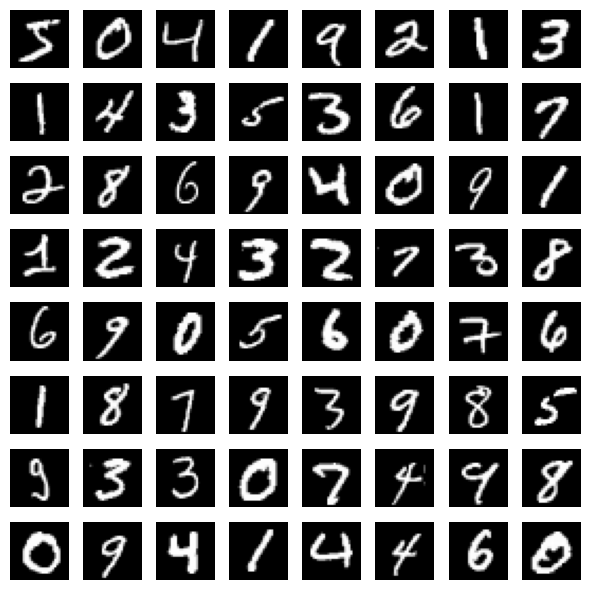

In [46]:
# original data
plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    plt.imshow(fixed_x[i].cpu().squeeze().numpy(), cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# encoder
z_dim = 64
E = VAE_Encoder_MNIST(latent_dim=z_dim).to(device)
E.load_state_dict(torch.load("./save_model/E_invert_to_G_C_only.pth"))
E.eval()
for p in E.parameters():
    p.requires_grad = False

G = Ganerator_MNIST(z_dim=z_dim).to(device)
G.load_state_dict(torch.load("./save_model/G_wgangp_C.pth"))
G.eval()
for p in G.parameters():
    p.requires_grad = False

In [48]:
# encode
with torch.no_grad():
    mu, logvar = E(fixed_x)
    fixed_z = mu

# 存 latent
z_np = fixed_z.detach().cpu().numpy()
# np.save("z_batch.npy", z_np)

print("z shape =", fixed_z.shape)
print("z =", fixed_z)

z shape = torch.Size([64, 64])
z = tensor([[-1.6295,  0.8370,  0.6788,  ...,  1.1010,  0.5539,  0.1863],
        [ 0.8947, -0.5868,  0.1144,  ..., -0.4430,  0.1828, -0.2075],
        [-1.7969, -1.5133, -0.6035,  ...,  0.9282,  0.5499, -0.6625],
        ...,
        [-1.8716,  1.0663,  2.3253,  ..., -0.0106,  0.5696, -2.3708],
        [-2.0977, -1.5219,  1.8638,  ..., -0.9131,  0.5826,  0.6633],
        [-0.8484,  1.0428, -0.0684,  ..., -0.2647,  0.2548,  1.0055]],
       device='cuda:0')


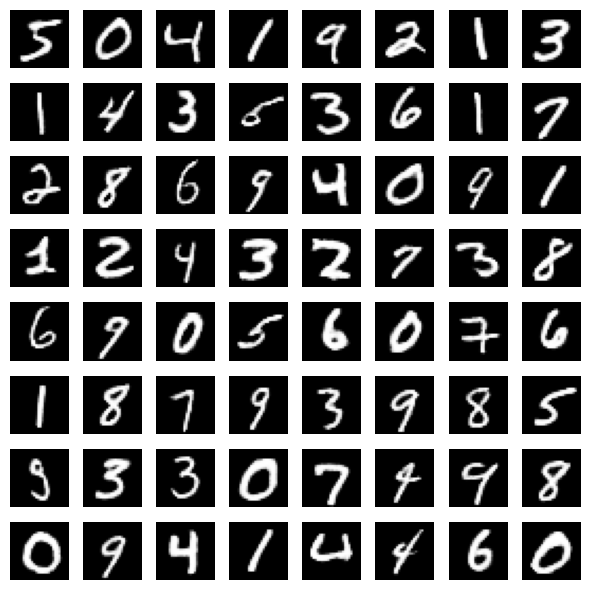

In [49]:
z_in = fixed_z.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
# reconstruct
with torch.no_grad():
    x_gen_orig = G(z_in)

plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    img = ((x_gen_orig[i] + 1) / 2).cpu().squeeze().numpy()
    plt.imshow(img, cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

save_image((x_gen_orig.cpu() + 1) / 2, "./save_data/lloyd_max_codebook/gen_x.png", nrow=8)

In [50]:
# 這裡停在測試完VAE encoder 做完 encode 
# 做量化
# 做復原然後做量化前後對比
# 解決問題:
#   1. transformer的不同會造成解出的結果有誤差
#   2. 有無normalization也有差
# 待解決: 
#   1. 要不要對gan也新增label來提升encoder對於 decode的結果做提升，畢竟DM都需要label了
#      是否passdown 的差別而已
# 2026.03.11

In [51]:
# 統計經過encode後的數據
# 1.先統計每個data經過code之後的數據
# 2.做8 bits(256)、7 bits(128)、6 bits(64)、5 bits(32)的uniform quantization
all_z = []

E.eval()

with torch.no_grad():
    for x, _ in dl:

        x = x.to(device)

        mu, logvar = E(x)   # VAE encoder
        z = mu              # 通常 encode 用 mean

        all_z.append(z.cpu())

all_z = torch.cat(all_z, dim=0)

print("latent shape:", all_z.shape)
print("min:", all_z.min())
print("max:", all_z.max())
print("mean:", all_z.mean())
print("std:", all_z.std())

latent shape: torch.Size([60000, 64])
min: tensor(-6.4575)
max: tensor(6.5964)
mean: tensor(-0.0315)
std: tensor(1.1503)


In [67]:
i = 50
for j in range (1,9):
    bits = j
    # b_list = []
    # q_list = []
    # test_iter = [50,70,100,120]
    # for i in test_iter:
    q,b = lloyd_max (all_z, max_iter=i, K=2**bits)
    # b_list.append(b)
    # q_list.append(q)
    print(f"boundaries (iter={i}):")
    print(b)
    # print(b_list)
    torch.save({
        "q": q,
        "b": b,
    }, f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}.pth")

boundaries (iter=50):
tensor([-0.0441])
boundaries (iter=50):
tensor([-1.1902, -0.0480,  1.0797])
boundaries (iter=50):
tensor([-2.1253, -1.2753, -0.6236, -0.0384,  0.5427,  1.1781,  1.9907])
boundaries (iter=50):
tensor([-3.2698, -2.5345, -2.0040, -1.5541, -1.1416, -0.7493, -0.3683,  0.0071,
         0.3807,  0.7569,  1.1405,  1.5406,  1.9747,  2.4798,  3.1672])
boundaries (iter=50):
tensor([-4.9608, -4.4306, -4.0276, -3.6619, -3.3148, -2.9767, -2.6495, -2.3345,
        -2.0278, -1.7253, -1.4259, -1.1293, -0.8347, -0.5423, -0.2513,  0.0389,
         0.3284,  0.6179,  0.9073,  1.1970,  1.4890,  1.7841,  2.0822,  2.3841,
         2.6930,  3.0137,  3.3508,  3.7129,  4.1108,  4.5844,  5.2405])
boundaries (iter=50):
tensor([-6.2875, -5.9879, -5.6995, -5.4167, -5.1810, -4.9496, -4.7242, -4.5163,
        -4.3091, -4.1057, -3.9090, -3.7129, -3.5186, -3.3221, -3.1223, -2.9234,
        -2.7272, -2.5345, -2.3457, -2.1595, -1.9736, -1.7869, -1.6000, -1.4140,
        -1.2287, -1.0437, -0.8592, -0.

{'q': tensor([-0.9578,  0.8695]), 'b': tensor([-0.0441])}
tensor([-0.0441])


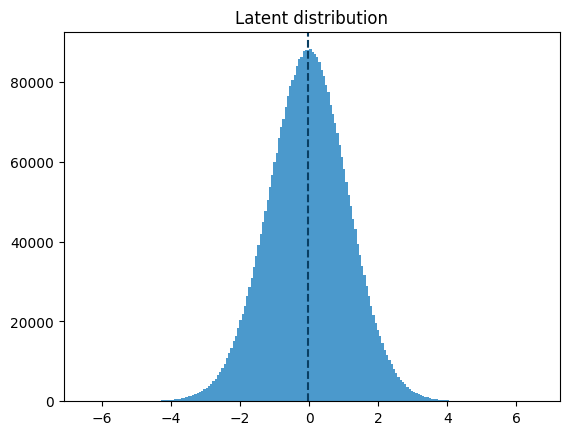

{'q': tensor([-1.8114, -0.5692,  0.4731,  1.6861]), 'b': tensor([-1.1902, -0.0480,  1.0797])}
tensor([-1.1902, -0.0480,  1.0797])


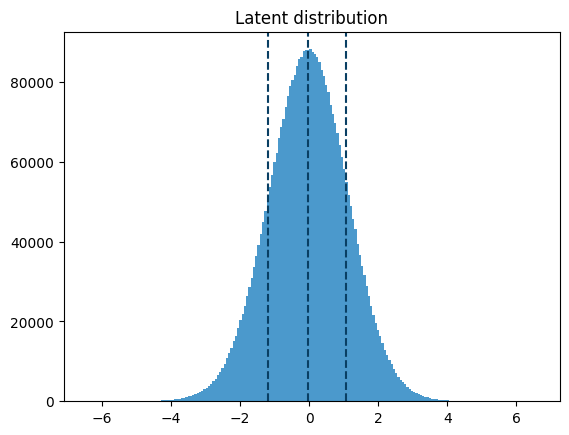

{'q': tensor([-2.6239, -1.6268, -0.9241, -0.3238,  0.2460,  0.8379,  1.5168,  2.4630]), 'b': tensor([-2.1253, -1.2753, -0.6236, -0.0384,  0.5427,  1.1781,  1.9907])}
tensor([-2.1253, -1.2753, -0.6236, -0.0384,  0.5427,  1.1781,  1.9907])


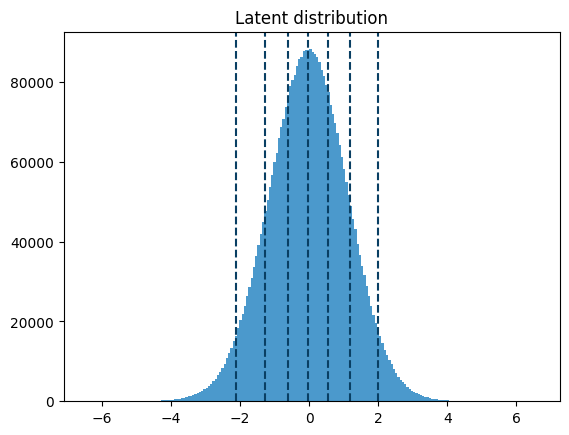

{'q': tensor([-3.7004, -2.8158, -2.2304, -1.7571, -1.3337, -0.9361, -0.5538, -0.1790,
         0.1919,  0.5632,  0.9395,  1.3262,  1.7357,  2.1909,  2.7429,  3.5634]), 'b': tensor([-3.2698, -2.5345, -2.0040, -1.5541, -1.1416, -0.7493, -0.3683,  0.0071,
         0.3807,  0.7569,  1.1405,  1.5406,  1.9747,  2.4798,  3.1672])}
tensor([-3.2698, -2.5345, -2.0040, -1.5541, -1.1416, -0.7493, -0.3683,  0.0071,
         0.3807,  0.7569,  1.1405,  1.5406,  1.9747,  2.4798,  3.1672])


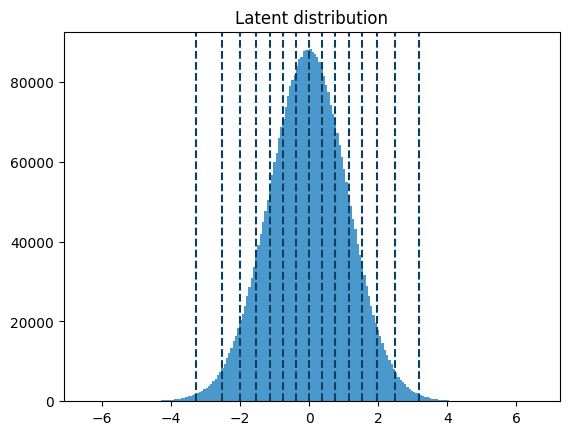

{'q': tensor([-5.2723, -4.6279, -4.1976, -3.8193, -3.4687, -3.1280, -2.7954, -2.4766,
        -2.1690, -1.8665, -1.5668, -1.2707, -0.9764, -0.6846, -0.3946, -0.1055,
         0.1828,  0.4704,  0.7586,  1.0461,  1.3351,  1.6271,  1.9220,  2.2196,
         2.5221,  2.8341,  3.1608,  3.5053,  3.8787,  4.2983,  4.8349,  5.6209]), 'b': tensor([-4.9608, -4.4306, -4.0276, -3.6619, -3.3148, -2.9767, -2.6495, -2.3345,
        -2.0278, -1.7253, -1.4259, -1.1293, -0.8347, -0.5423, -0.2513,  0.0389,
         0.3284,  0.6179,  0.9073,  1.1970,  1.4890,  1.7841,  2.0822,  2.3841,
         2.6930,  3.0137,  3.3508,  3.7129,  4.1108,  4.5844,  5.2405])}
tensor([-4.9608, -4.4306, -4.0276, -3.6619, -3.3148, -2.9767, -2.6495, -2.3345,
        -2.0278, -1.7253, -1.4259, -1.1293, -0.8347, -0.5423, -0.2513,  0.0389,
         0.3284,  0.6179,  0.9073,  1.1970,  1.4890,  1.7841,  2.0822,  2.3841,
         2.6930,  3.0137,  3.3508,  3.7129,  4.1108,  4.5844,  5.2405])


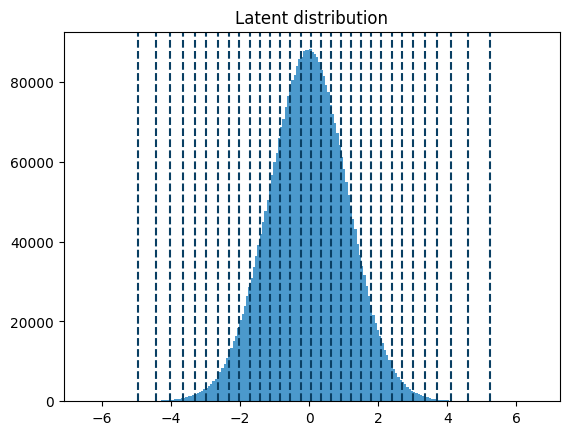

{'q': tensor([-6.4575, -6.1175, -5.8584, -5.5363, -5.2861, -5.0612, -4.8240, -4.6130,
        -4.4073, -4.1975, -4.0011, -3.8037, -3.6073, -3.4148, -3.2157, -3.0160,
        -2.8186, -2.6249, -2.4342, -2.2478, -2.0623, -1.8768, -1.6898, -1.5037,
        -1.3186, -1.1337, -0.9493, -0.7655, -0.5810, -0.3971, -0.2138, -0.0307,
         0.1520,  0.3343,  0.5175,  0.7010,  0.8837,  1.0665,  1.2499,  1.4327,
         1.6167,  1.8007,  1.9851,  2.1694,  2.3553,  2.5416,  2.7312,  2.9227,
         3.1164,  3.3088,  3.5104,  3.7211,  3.9387,  4.1649,  4.3925,  4.6243,
         4.8733,  5.1452,  5.4627,  5.6831,  5.8894,  6.0417,  6.3892,  6.5964]), 'b': tensor([-6.2875, -5.9879, -5.6995, -5.4167, -5.1810, -4.9496, -4.7242, -4.5163,
        -4.3091, -4.1057, -3.9090, -3.7129, -3.5186, -3.3221, -3.1223, -2.9234,
        -2.7272, -2.5345, -2.3457, -2.1595, -1.9736, -1.7869, -1.6000, -1.4140,
        -1.2287, -1.0437, -0.8592, -0.6747, -0.4901, -0.3061, -0.1225,  0.0608,
         0.2438,  0.4269,  

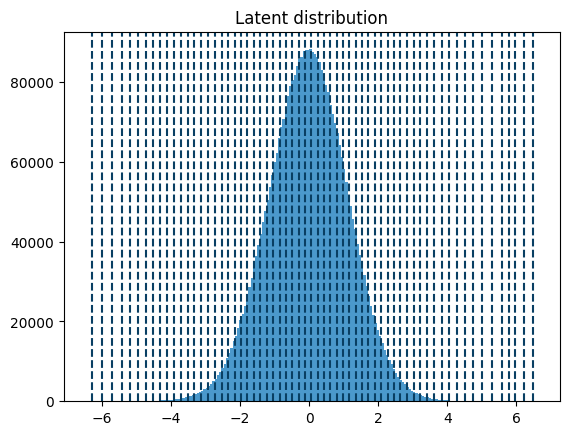

{'q': tensor([-6.4575, -6.3547, -6.2519, -6.1619, -6.0731, -5.9448, -5.8238, -5.7722,
        -5.6594, -5.5384, -5.4403, -5.3194, -5.2192, -5.1233, -5.0185, -4.8960,
        -4.7620, -4.6539, -4.5376, -4.4261, -4.3143, -4.2076, -4.1096, -4.0051,
        -3.9006, -3.8000, -3.6964, -3.5941, -3.4956, -3.3933, -3.2908, -3.1886,
        -3.0869, -2.9831, -2.8796, -2.7762, -2.6738, -2.5744, -2.4730, -2.3723,
        -2.2724, -2.1719, -2.0716, -1.9725, -1.8737, -1.7743, -1.6752, -1.5758,
        -1.4759, -1.3758, -1.2761, -1.1763, -1.0767, -0.9769, -0.8770, -0.7778,
        -0.6783, -0.5790, -0.4797, -0.3798, -0.2803, -0.1806, -0.0813,  0.0179,
         0.1172,  0.2164,  0.3156,  0.4152,  0.5148,  0.6142,  0.7137,  0.8130,
         0.9122,  1.0113,  1.1107,  1.2106,  1.3103,  1.4097,  1.5092,  1.6088,
         1.7075,  1.8067,  1.9063,  2.0058,  2.1055,  2.2052,  2.3049,  2.4046,
         2.5041,  2.6039,  2.7046,  2.8042,  2.9052,  3.0072,  3.1084,  3.2100,
         3.3111,  3.4189,  3.5257,

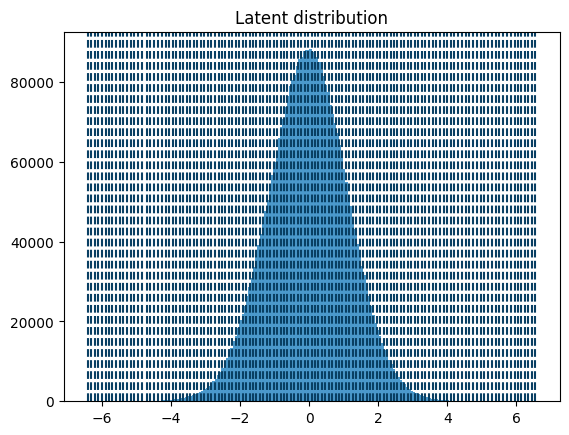

{'q': tensor([-6.4575, -6.4063, -6.3551, -6.3039, -6.2527, -6.2015, -6.1619, -6.0992,
        -6.0731, -5.9968, -5.9448, -5.8944, -5.8371, -5.7933, -5.7408, -5.6756,
        -5.6522, -5.5857, -5.5328, -5.4712, -5.4148, -5.3632, -5.3143, -5.2764,
        -5.2221, -5.1691, -5.1282, -5.0744, -5.0204, -4.9576, -4.9084, -4.8563,
        -4.7995, -4.7491, -4.7050, -4.6626, -4.6033, -4.5497, -4.4958, -4.4473,
        -4.4008, -4.3554, -4.3064, -4.2560, -4.2055, -4.1515, -4.0984, -4.0417,
        -3.9909, -3.9373, -3.8819, -3.8323, -3.7855, -3.7322, -3.6831, -3.6336,
        -3.5813, -3.5296, -3.4777, -3.4255, -3.3730, -3.3213, -3.2703, -3.2192,
        -3.1676, -3.1181, -3.0677, -3.0154, -2.9619, -2.9096, -2.8568, -2.8053,
        -2.7539, -2.7014, -2.6491, -2.5981, -2.5476, -2.4972, -2.4466, -2.3963,
        -2.3466, -2.2961, -2.2457, -2.1951, -2.1438, -2.0920, -2.0413, -1.9903,
        -1.9397, -1.8880, -1.8363, -1.7848, -1.7342, -1.6837, -1.6324, -1.5816,
        -1.5304, -1.4798, -1.4288,

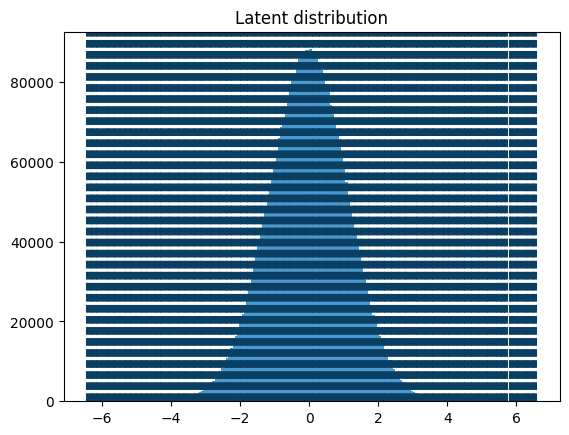

In [68]:
for i in range(1,9):
    bits = i
    lloyd_max_codebook = torch.load(f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}.pth")
    print(lloyd_max_codebook)
    q = lloyd_max_codebook["q"]
    b = lloyd_max_codebook["b"]
    print(b)
    plt.hist(all_z.flatten().numpy(), color='#4b99cc', bins=200)
    for val in b:   # b: lloyd-max 的 boundaries
        plt.axvline(val.item(), color='#093f63', linestyle='--')
    plt.title("Latent distribution")
    plt.show()

In [59]:
def mse(img1, img2):
    return torch.mean((img1 - img2) ** 2)

def psnr(img1, img2):
    mse_val = torch.mean((img1 - img2) ** 2)
    return 20 * torch.log10(1.0 / torch.sqrt(mse_val))

def compute_ssim(img1, img2):
    return ssim(img1, img2, data_range=1.0)

1
=== Uniform ===
MSE: 0.1153908520936966
PSNR: 9.378286361694336
SSIM: 0.2361893653869629
SSIM: 0.2361893653869629

=== Lloyd ===
MSE: 0.07965821772813797
PSNR: 10.987693786621094
SSIM: 0.34856364130973816
2
=== Uniform ===
MSE: 0.08253161609172821
PSNR: 10.833796501159668
SSIM: 0.3504619598388672
SSIM: 0.3504619598388672

=== Lloyd ===
MSE: 0.04068104177713394
PSNR: 13.90608024597168
SSIM: 0.6173479557037354
3
=== Uniform ===
MSE: 0.03057917393743992
PSNR: 15.145742416381836
SSIM: 0.6998358368873596
SSIM: 0.6998358368873596

=== Lloyd ===
MSE: 0.016226716339588165
PSNR: 17.897693634033203
SSIM: 0.8324527740478516
4
=== Uniform ===
MSE: 0.008109661750495434
PSNR: 20.90997314453125
SSIM: 0.8980937004089355
SSIM: 0.8980937004089355

=== Lloyd ===
MSE: 0.0053240773268043995
PSNR: 22.73755645751953
SSIM: 0.9300376772880554
5
=== Uniform ===
MSE: 0.002109803957864642
PSNR: 26.75758171081543
SSIM: 0.9739223718643188
SSIM: 0.9739223718643188

=== Lloyd ===
MSE: 0.0028784447349607944
PSNR: 25

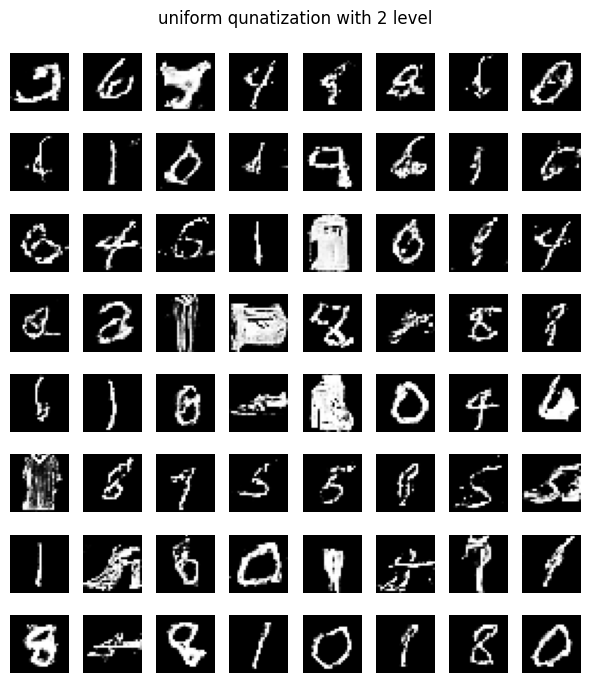

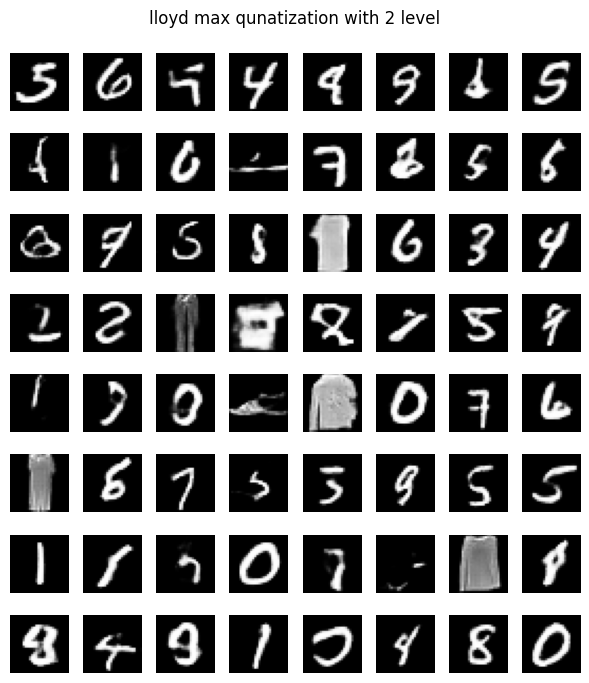

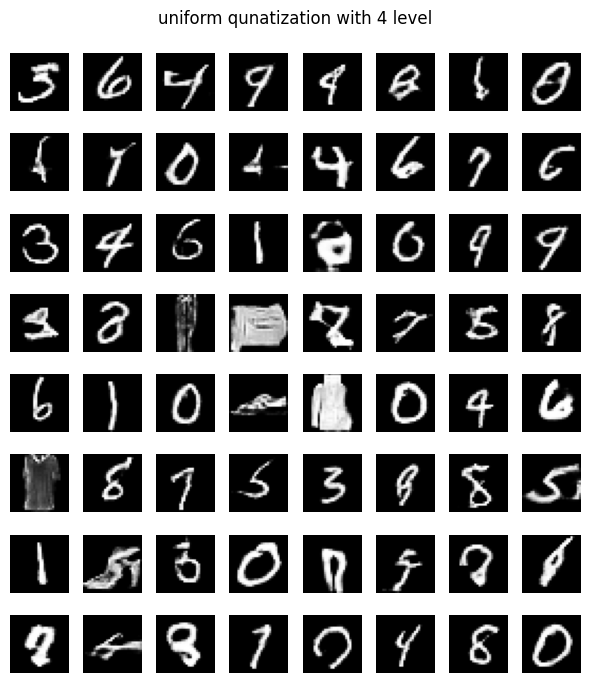

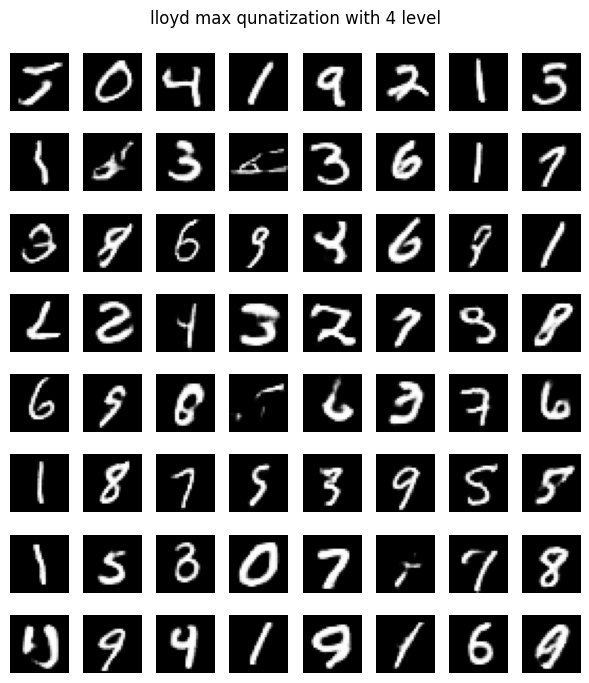

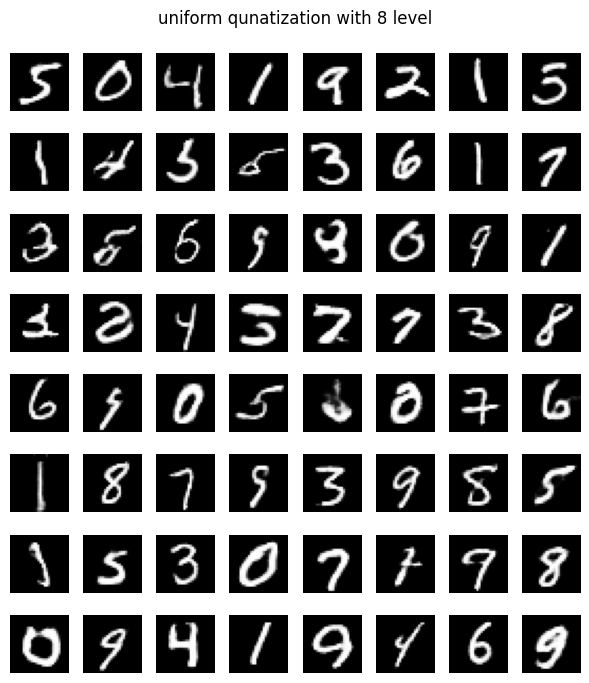

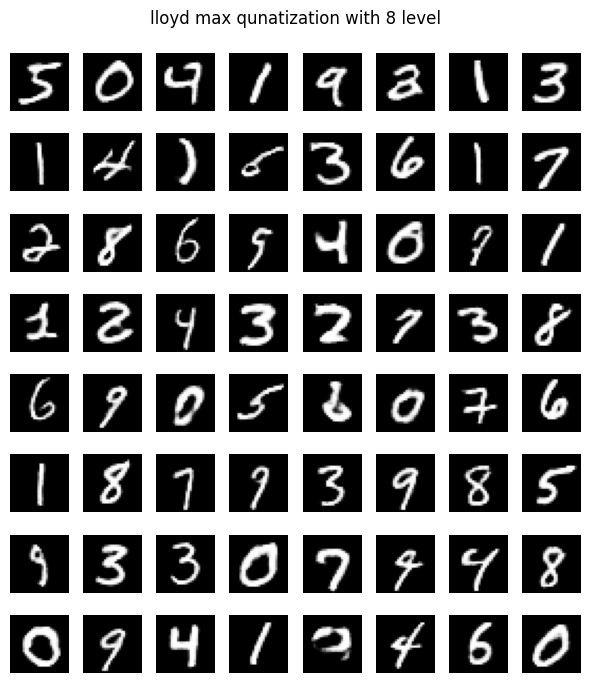

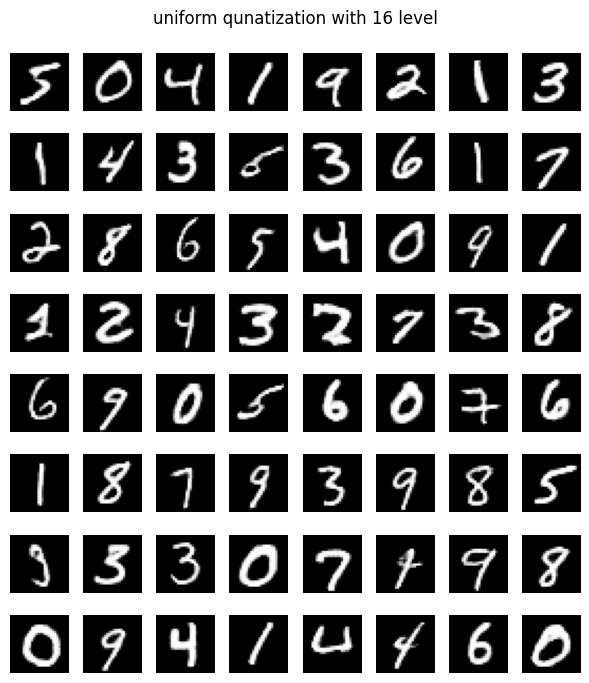

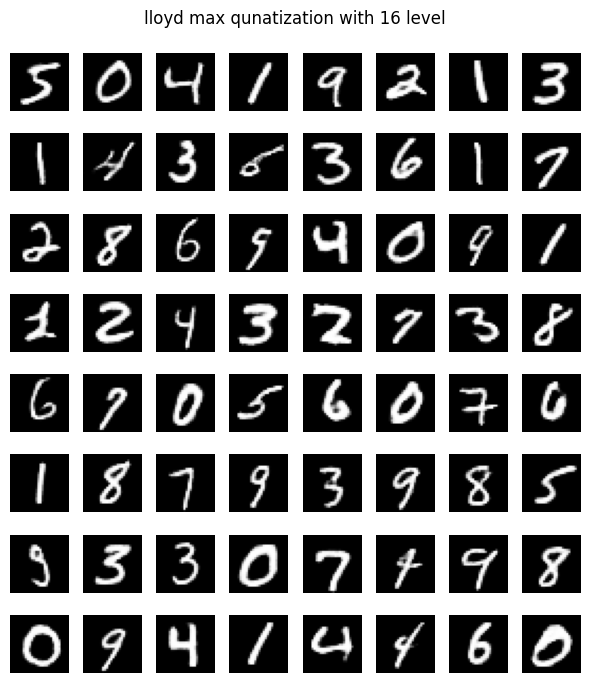

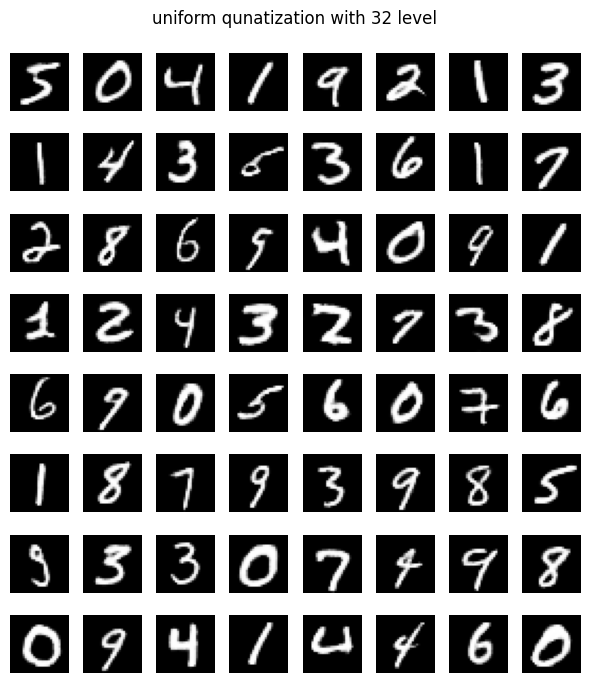

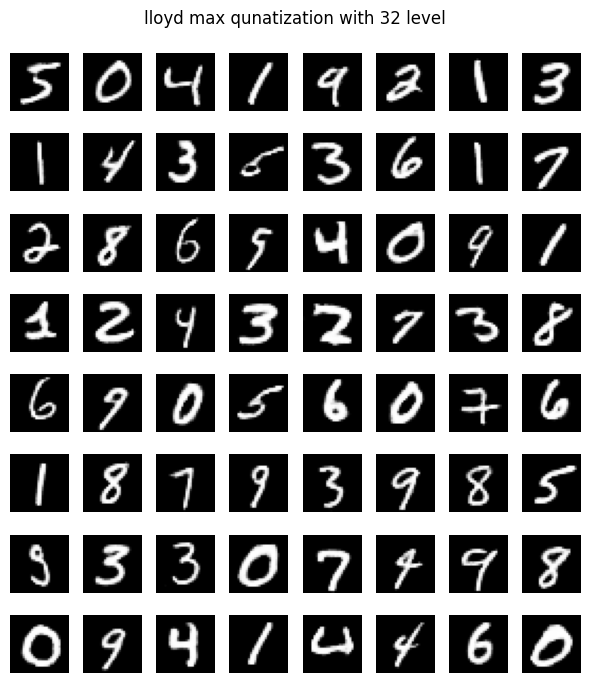

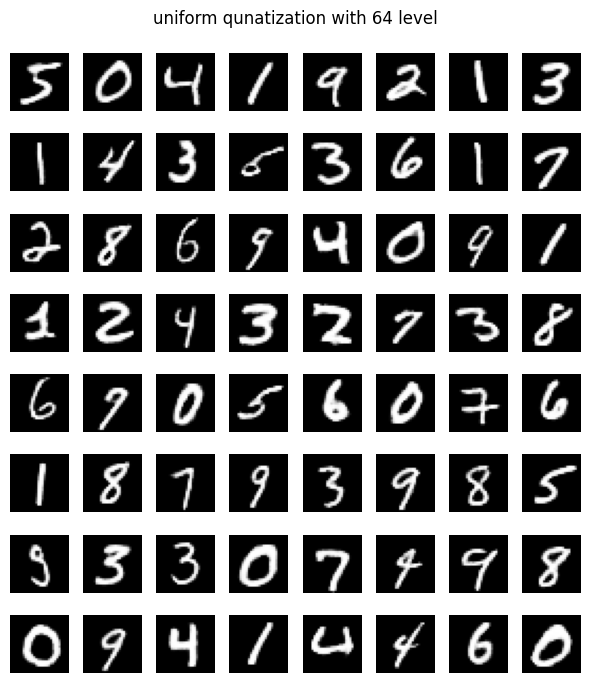

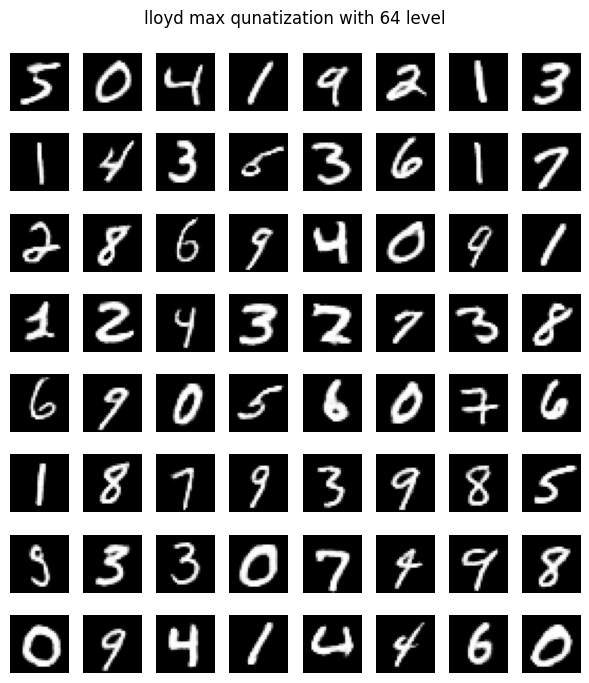

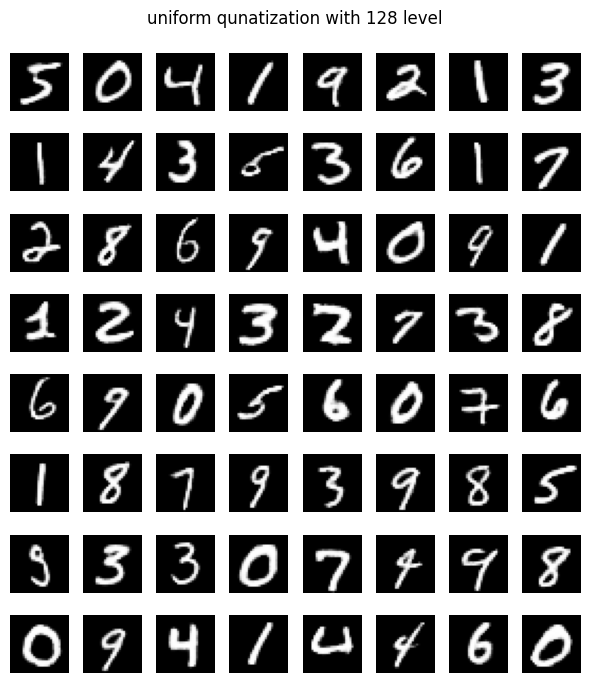

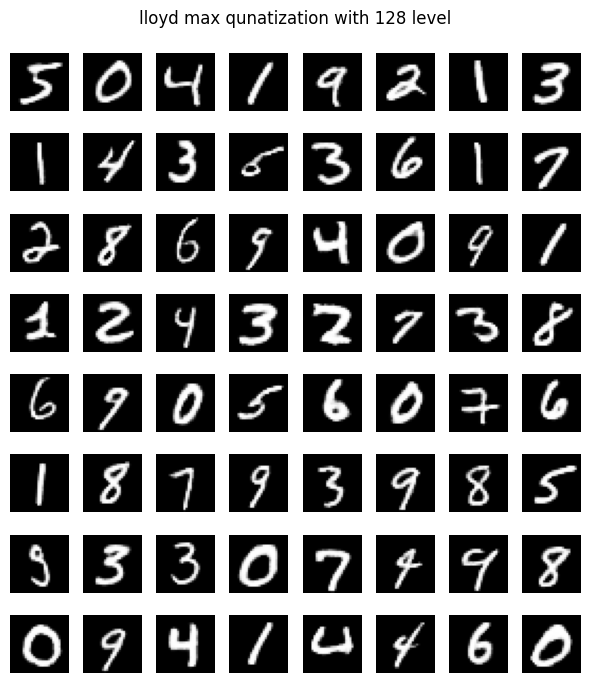

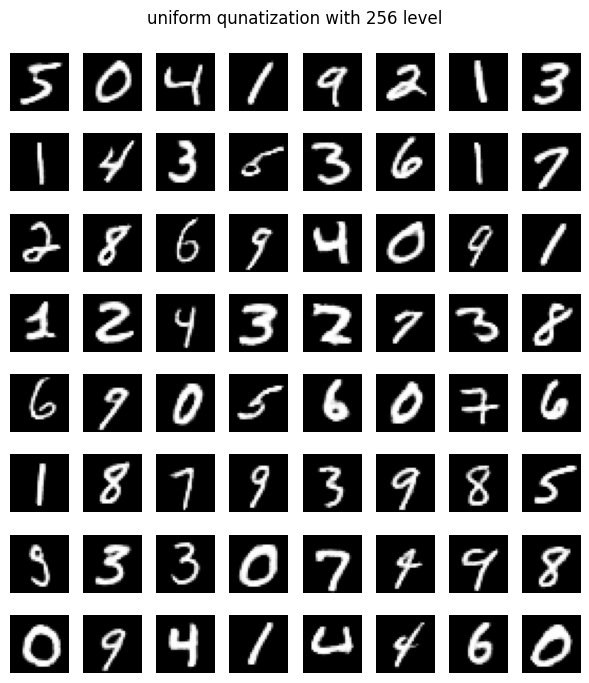

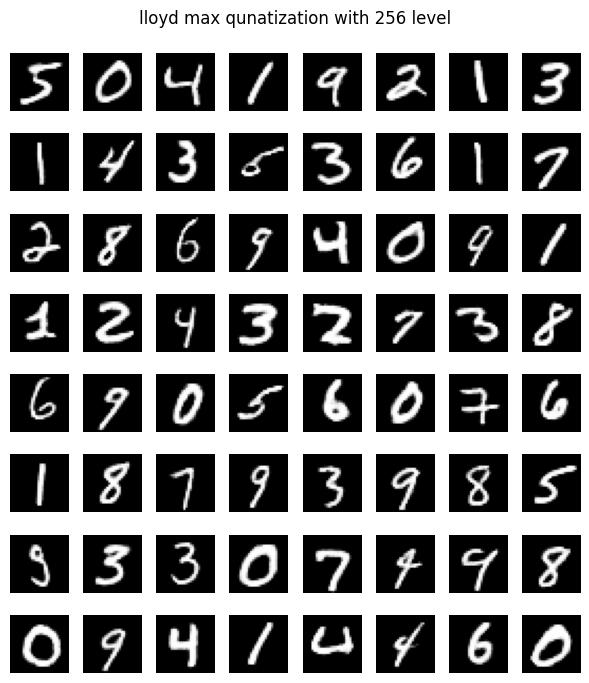

In [70]:
uni_mse = []
uni_psnr = []
uni_ssim = []
llo_mse = []
llo_psnr = []
llo_ssim = []
for i in range(1,9):
    bits = i
    print(bits)
    lloyd_max_codebook = torch.load(f"./save_data/lloyd_max_codebook/lloyd_codebook_{2**bits}.pth")
    # print(lloyd_max_codebook)
    q = lloyd_max_codebook["q"]
    b = lloyd_max_codebook["b"]
    
    z_q_uni, z_rec_uni, scale_uni = quantization(fixed_z,bits=bits)
    z_q_llo, z_rec_llo, _= quantization(fixed_z,type='lloyd',q=q,b=b)
    # print("uni")
    # print(z_q_uni)
    # print("lloyd")
    # print(z_q_llo)
    z_rec_uni = dequantization(z_q_uni,bits=bits)
    # print("uni")
    # print(z_rec_uni)
    z_rec_llo = dequantization(z_q_llo,type='lloyd',q=q)
    # print("lloyd")
    # print(z_rec_llo)
    z_rec_uni = z_rec_uni.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    z_rec_llo = z_rec_llo.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    with torch.no_grad():
        z_gen_uni = G(z_rec_uni)
        z_gen_llo = G(z_rec_llo)

    img = (x_gen_orig + 1) / 2
    img_uni = (z_gen_uni + 1) / 2
    img_llo = (z_gen_llo + 1) / 2
    print("=== Uniform ===")
    print("MSE:", mse(img, img_uni).item())
    print("PSNR:", psnr(img, img_uni).item())
    print("SSIM:", compute_ssim(img, img_uni).item())
    unimse = mse(img, img_uni).item()
    unipsnr = psnr(img, img_uni).item()
    unissim = compute_ssim(img, img_uni).item()
    uni_mse.append(unimse)
    uni_psnr.append(unipsnr)
    uni_ssim.append(unissim)
    print("SSIM:", compute_ssim(img, img_uni).item())
    print("\n=== Lloyd ===")
    print("MSE:", mse(img, img_llo).item())
    print("PSNR:", psnr(img, img_llo).item())
    print("SSIM:", compute_ssim(img, img_llo).item())
    unimse = mse(img, img_llo).item()
    unipsnr = psnr(img, img_llo).item()
    unissim = compute_ssim(img, img_llo).item()
    llo_mse.append(unimse)
    llo_psnr.append(unipsnr)
    llo_ssim.append(unissim)
    plt.figure(figsize=(6,7))
    for i in range(64):
        plt.subplot(8, 8, i+1)
        img = ((z_gen_uni[i] + 1) / 2).cpu().squeeze().numpy()
        plt.imshow(img, cmap='gray')
        plt.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.suptitle(f"uniform qunatization with {2**bits} level",fontsize=12)
    # plt.show()
    save_image((z_gen_uni.cpu() + 1) / 2, f"./save_data/lloyd_max_codebook/z_gen_uni_{2**bits}.png", nrow=8)

    plt.figure(figsize=(6,7))
    for i in range(64):
        plt.subplot(8, 8, i+1)
        img = ((z_gen_llo[i] + 1) / 2).cpu().squeeze().numpy()
        plt.imshow(img, cmap='gray')
        plt.axis("off")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.suptitle(f"lloyd max qunatization with {2**bits} level",fontsize=12)
    # plt.show()
    save_image((z_gen_llo.cpu() + 1) / 2, f"./save_data/lloyd_max_codebook/z_gen_lloyd_{2**bits}.png", nrow=8)

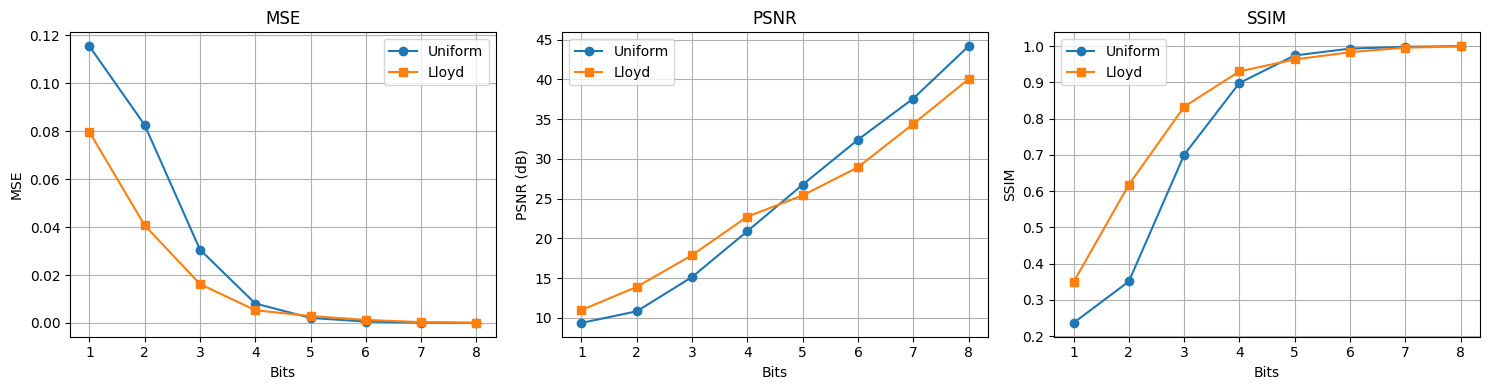

In [71]:
bits_list = list(range(1, 9))  # 你的 bits 範圍

plt.figure(figsize=(15, 4))

# ===== MSE =====
plt.subplot(1, 3, 1)
plt.plot(bits_list, uni_mse, marker='o', label='Uniform')
plt.plot(bits_list, llo_mse, marker='s', label='Lloyd')
plt.title("MSE")
plt.xlabel("Bits")
plt.ylabel("MSE")
plt.legend()
plt.grid()

# ===== PSNR =====
plt.subplot(1, 3, 2)
plt.plot(bits_list, uni_psnr, marker='o', label='Uniform')
plt.plot(bits_list, llo_psnr, marker='s', label='Lloyd')
plt.title("PSNR")
plt.xlabel("Bits")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.grid()

# ===== SSIM =====
plt.subplot(1, 3, 3)
plt.plot(bits_list, uni_ssim, marker='o', label='Uniform')
plt.plot(bits_list, llo_ssim, marker='s', label='Lloyd')
plt.title("SSIM")
plt.xlabel("Bits")
plt.ylabel("SSIM")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
# 做量化對還原的影響
# 從8bits到3bits 
# 大概到4bits的時候會有比較顯著的錯誤出現
# 統計結果是高斯分布 max在4 min是-4
# 2026.03.13

In [ ]:
E.eval()

bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

codebook_dir = f"./save_data/lloyd_max_codebook/lloyd_codebook_{bits}.pth"
codebook = torch.load(codebook_dir,
    map_location="cpu")
q = codebook["q"]
b = codebook["b"]
# print(type(codebook))
# print(codebook)

save_dir = F"./latent_bits_M/bits_{bits}/uni"
save_dir_llo = F"./latent_bits_M/bits_{bits}/llo"
save_dir_latent = F"./latent_bits_M/bits_{bits}/latent"
os.makedirs(save_dir, exist_ok=True)

dataset = dl.dataset
N = len(dataset)

for i,  (x, y) in enumerate(dl):
    print(i, x.shape, y.shape)
    print(y)
    # if i==1:
    #     break
    
    x = x.to(device)
    # ------------------------
    # encode
    # ------------------------
    with torch.no_grad():
        mu, logvar = E(x)
        z = mu.squeeze(0)
    # print("latent")
    # print(z)
    # ------------------------
    # quantization
    # ------------------------
    z_q,_,_ = quantization (z,bits)
    z_q_lloyd,_,_ = quantization (z,bits,type="lloyd",q=q,b=b)
    # print("===== z_q =====")
    # print("type:", type(z_q))
    # print("dtype:", z_q.dtype)
    # print("shape:", z_q.shape)
    # print("numel:", z_q.numel())   # 總元素數
    # print()
    # print("quan")
    # print(z_q)
    # ------------------------
    # 轉 bit
    # ------------------------
    bits_array = array_to_bits(z_q, bit_width=bits)
    bits_array_lloyd = array_to_bits(z_q_lloyd, bit_width=bits)
    # print("===== bits_array =====")
    # print("type:", type(bits_array))
    # if isinstance(bits_array, torch.Tensor):
    #     print("dtype:", bits_array.dtype)
    #     print("shape:", bits_array.shape)
    #     print("numel:", bits_array.numel())
    # else:
    #     print("len:", len(bits_array))
    # print("to bit")
    # print(bits_array)
    #------------------------
    # 加上header
    # -----------------------
    idx_bits = np.array(list(f"{i:012b}"),dtype=np.float64)
    print("i=",i,'  ',idx_bits)
    dataset_bits = [0,0,0,0]

    loadbits_0 = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0] # 16 bits
    loadbits_1 = [1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]
    # 接到 bits 前面
    bits_with_idx = np.concatenate([loadbits_0, idx_bits, dataset_bits, loadbits_0, idx_bits, dataset_bits, bits_array]) # 64 bits
    bits_with_idx_lloyd = np.concatenate([loadbits_0, idx_bits, dataset_bits, loadbits_0, idx_bits, dataset_bits, bits_array_lloyd])
    print( len(bits_with_idx))
    # ------------------------
    # 轉回array
    # ------------------------
    # array = bits_to_array(bits_array, bit_width=bits)
    # print("to array")
    # print(array)
    # ------------------------
    # dequantization
    # ------------------------
    # z_deq = dequantization (array,bits)
    # print("dequan")
    # print(z_deq)
    # ------------------------
    # 存 MAT
    # ------------------------
    # for j in range(mu.size(0)):

    #     z = mu[j]

    #     z_q, _, _ = quantization(z, bits)

    #     bits_array = array_to_bits(
    #         z_q,
    #         bit_width=bits
    #     )

    savemat(
        f"{save_dir}/sample_{i:05d}.mat",
        {"bits": bits_with_idx.astype(np.float64)}
    )
    savemat(
        f"{save_dir_llo}/sample_{i:05d}.mat",
        {"bits": bits_with_idx_lloyd.astype(np.float64)}
    )
    savemat(
            f"{save_dir_latent}/latent_{i:05d}.mat",
            {
                "id": np.array([i], dtype=np.int32),
                "latent": mu.detach().cpu().numpy(),
                "label": y.detach().cpu().numpy(),
            }
        )
    # print(f"saved {i}")
# print(i)

0 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7])
i= 0    [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
8256
1 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([2, 8, 6, 9, 4, 0, 9, 1, 1, 2, 4, 3, 2, 7, 3, 8])
i= 1    [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
8256
2 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([6, 9, 0, 5, 6, 0, 7, 6, 1, 8, 7, 9, 3, 9, 8, 5])
i= 2    [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
8256
3 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([9, 3, 3, 0, 7, 4, 9, 8, 0, 9, 4, 1, 4, 4, 6, 0])
i= 3    [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1.]
8256
4 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([4, 5, 6, 1, 0, 0, 1, 7, 1, 6, 3, 0, 2, 1, 1, 7])
i= 4    [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
8256
5 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([9, 0, 2, 6, 7, 8, 3, 9, 0, 4, 6, 7, 4, 6, 8, 0])
i= 5    [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1.]
8256
6 torch.Size([16, 1, 28, 28]) torch.Size([16])
tensor([7, 8, 3, 1, 5, 

In [10]:
bits = 8
pre = loadmat("./save_data/clean.mat")
tar = loadmat("./save_data/target.mat")

pre_bits = pre["bits"]
tar_bits = tar["bits"]

print(pre_bits.shape)
print(tar_bits.shape)

# pre_arr = bits_to_array(
#             pre_bits,
#             bit_width=bits
#         )
# pre_deq = dequantization(pre_arr, bits)

tar_arr = bits_to_array(
            tar_bits,
            bit_width=bits
        )
tar_deq = dequantization(tar_arr, bits)



(1, 1)
(1, 512)


In [7]:
# ===== numpy / torch 處理 =====
# if not torch.is_tensor(pre_deq):
#     pre_deq = torch.tensor(pre_deq, dtype=torch.float32)

if not torch.is_tensor(tar_deq):
    tar_deq = torch.tensor(tar_deq, dtype=torch.float32)

# ===== reshape latent =====
# pre_z = pre_deq.view(1, z_dim, 1, 1).to(device)
tar_z = tar_deq.view(1, z_dim, 1, 1).to(device)

# ===== decode by generator =====
with torch.no_grad():
    # pre_img = G(pre_z)
    tar_img = G(tar_z)


In [24]:
path = f"./save_data/lloyd_max_codebook/lloyd_codebook_8.pth"
codebook = torch.load(path,
    map_location="cpu")
print(type(codebook))
print(codebook)

<class 'dict'>
{'q': tensor([-6.4575, -6.1175, -5.8584, -5.5363, -5.2861, -5.0612, -4.8240, -4.6130,
        -4.4073, -4.1975, -4.0011, -3.8037, -3.6073, -3.4148, -3.2157, -3.0160,
        -2.8186, -2.6249, -2.4342, -2.2478, -2.0623, -1.8768, -1.6898, -1.5037,
        -1.3186, -1.1337, -0.9493, -0.7655, -0.5810, -0.3971, -0.2138, -0.0307,
         0.1520,  0.3343,  0.5175,  0.7010,  0.8837,  1.0665,  1.2499,  1.4327,
         1.6167,  1.8007,  1.9851,  2.1694,  2.3553,  2.5416,  2.7312,  2.9227,
         3.1164,  3.3088,  3.5104,  3.7211,  3.9387,  4.1649,  4.3925,  4.6243,
         4.8733,  5.1452,  5.4627,  5.6831,  5.8894,  6.0417,  6.3892,  6.5964]), 'b': tensor([-6.2875, -5.9879, -5.6995, -5.4167, -5.1810, -4.9496, -4.7242, -4.5163,
        -4.3091, -4.1057, -3.9090, -3.7129, -3.5186, -3.3221, -3.1223, -2.9234,
        -2.7272, -2.5345, -2.3457, -2.1595, -1.9736, -1.7869, -1.6000, -1.4140,
        -1.2287, -1.0437, -0.8592, -0.6747, -0.4901, -0.3061, -0.1225,  0.0608,
         0.2